<h1 style="color: darkgray;font-family:san=serif;text-align:right;font-weight:bold;font-size:30px">Import Libraries</h1>

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random
import pickle
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from lib_file import lib_path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import os
for dirname,_,filenames in os.walk('SplittedData'):
    for filename in filenames:
        print(os.path.join(dirname,filename))

SplittedData\X_test.csv
SplittedData\X_train.csv
SplittedData\y_test.csv
SplittedData\y_train.csv


# Data Loading

In [3]:
X_train = pd.read_csv('SplittedData/X_train.csv')
X_test = pd.read_csv('SplittedData/X_test.csv')
y_train = pd.read_csv('SplittedData/y_train.csv')
y_test = pd.read_csv('SplittedData/y_test.csv')

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(553180, 19) (138296, 19) (553180, 1) (138296, 1)


In [4]:
X_train.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url
0,76,13,56,8,2,1,0,0,0,2,0,1,0,1,21,44,5,1,1
1,43,15,6,5,3,0,0,1,0,2,1,1,1,1,2,33,1,1,1
2,70,14,48,33,3,4,0,0,0,2,0,1,1,1,10,48,3,1,1
3,36,12,16,4,3,0,0,0,0,2,0,1,1,1,7,21,3,1,1
4,36,12,16,4,3,0,0,0,0,2,0,1,1,1,7,21,3,1,1


In [5]:
y_train.head()

,label
0,1
1,0
2,0
3,0
4,0


In [6]:
X_test.head()

,url_length,hostname_length,path_length,fd_length,tld_length,count-,count@,count?,count%,count.,count=,count-http,count-https,count-www,count-digits,count-letters,count_dir,use_of_ip,short_url
0,65,12,7,6,3,1,0,1,0,3,1,1,0,0,1,49,1,1,1
1,31,12,12,11,3,0,0,0,0,1,0,1,0,0,2,24,1,1,1
2,45,24,13,11,3,2,0,0,0,2,0,1,1,1,0,36,2,1,-1
3,105,15,82,6,3,10,0,0,0,2,0,1,1,1,8,78,4,1,1
4,48,12,28,7,3,1,0,0,0,3,0,1,1,1,0,38,3,1,1


In [7]:
y_test.head()

,label
0,1
1,1
2,0
3,0
4,0


# Algorithm-1 : RandomForestClassifier

In [8]:
from sklearn.ensemble import RandomForestClassifier

rfc_model = RandomForestClassifier(n_estimators=1, min_samples_split=5000, min_samples_leaf=5000)
rfc_model = rfc_model.fit(X_train.values, y_train.values.ravel())

In [9]:
rfc_prediction = rfc_model.predict(X_test.values)
print(rfc_prediction.tolist())

[1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 

In [10]:
y_true = y_test.values.ravel().tolist()
print(y_true)

[1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 

### Result Analysis

In [11]:
class_labels = ['benign', 'malicious']

***Accuracy Score***

In [12]:
rfc_model_accuracy = accuracy_score(y_true=y_true, y_pred=rfc_prediction)
print("Validation accuracy of RandomForestClassifier model is {:.2f}%".format(rfc_model_accuracy*100))

Validation accuracy of RandomForestClassifier model is 97.80%


***Classification Report***

In [13]:
print(classification_report(y_true=y_true, y_pred=rfc_prediction, target_names=class_labels))

              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     69148
   malicious       1.00      0.96      0.98     69148

    accuracy                           0.98    138296
   macro avg       0.98      0.98      0.98    138296
weighted avg       0.98      0.98      0.98    138296



***Confusion Matrix***

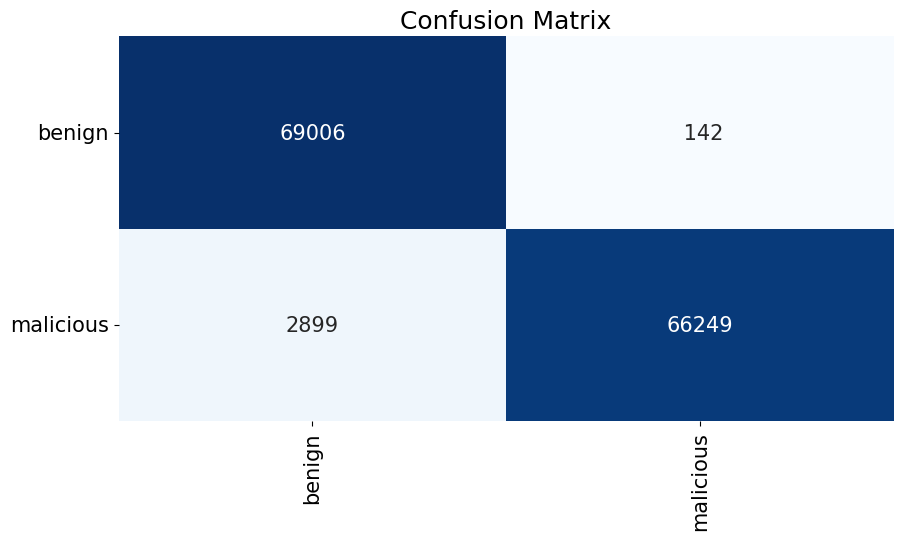

In [14]:
plt.figure(figsize=(10,5))
plt.rcParams['font.size'] = 15
sns.heatmap(data=confusion_matrix(y_true=y_true,y_pred=rfc_prediction),
                                      annot=True,
                                      cmap=plt.cm.Blues,
                                      fmt = "4d",
                                      xticklabels=class_labels,
                                      yticklabels=class_labels,
                                      cbar=False)
plt.title(label="Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

***Model Saving***

In [15]:
with open(file="models/RandomForestClassifier_model.pkl", mode="wb") as file:
    pickle.dump(obj=rfc_model, file=file)

---

# Algorithm-2 : SupportVectorClassifier

In [ ]:
from sklearn.svm import SVC

svc_model = SVC()
svc_model = svc_model.fit(X_train.values, y_train.values.ravel())

In [16]:
svc_prediction = svc_model.predict(X_test.values)
print(svc_prediction.tolist())

[0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 

In [17]:
y_true = y_test.values.ravel().tolist()
print(y_true)

[1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 

### Result Analysis

In [18]:
class_labels = ['benign', 'malicious']

***Accuracy Score***

In [19]:
svc_model_accuracy = accuracy_score(y_true=y_true, y_pred=svc_prediction)
print("Validation accuracy of SupportVectorClassifier model is {:.2f}%".format(svc_model_accuracy*100))

Validation accuracy of SupportVectorClassifier model is 84.90%


***Classification Report***

In [20]:
print(classification_report(y_true=y_true, y_pred=svc_prediction, target_names=class_labels))

              precision    recall  f1-score   support

      benign       0.86      0.84      0.85     69148
   malicious       0.84      0.86      0.85     69148

    accuracy                           0.85    138296
   macro avg       0.85      0.85      0.85    138296
weighted avg       0.85      0.85      0.85    138296



***Confusion Matrix***

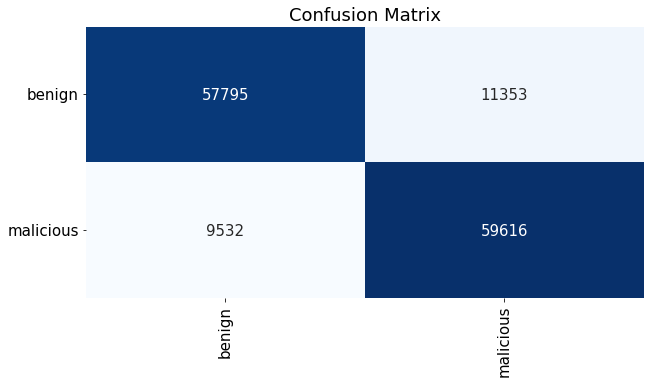

In [21]:
plt.figure(figsize=(10,5))
plt.rcParams['font.size'] = 15
sns.heatmap(data=confusion_matrix(y_true=y_true,y_pred=svc_prediction),
                                      annot=True,
                                      cmap=plt.cm.Blues,
                                      fmt = "4d",
                                      xticklabels=class_labels,
                                      yticklabels=class_labels,
                                      cbar=False)
plt.title(label="Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

***Model Saving***

In [22]:
with open(file="models/SupportVectorClassifier_model.pkl", mode="wb") as file:
    pickle.dump(obj=svc_model, file=file)

---

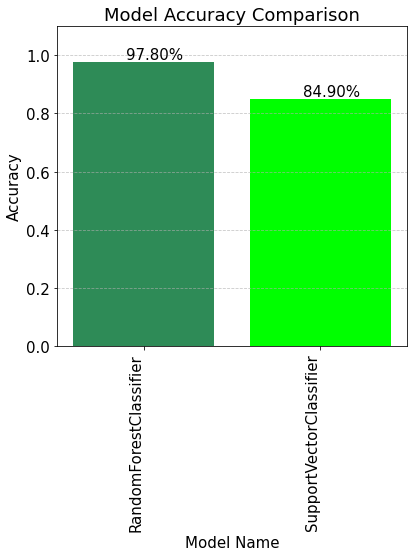

In [23]:
model_name = ["RandomForestClassifier", "SupportVectorClassifier"]
accuracy = [rfc_model_accuracy, svc_model_accuracy]

plt.figure(figsize=(6, 8))
bars = plt.bar(model_name, accuracy, color=['seagreen', 'lime'])

for bar, acc in zip(bars, accuracy):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, bar.get_height() + 0.01, f'{acc:.2%}', fontsize=15)

plt.title('Model Accuracy Comparison')
plt.xlabel('Model Name')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()

plt.show()

---

---